# Lampiran: Analisis Lanjutan Pindar Risk Atlas

Notebook ini berisi analisis yang dikeluarkan dari `pindar_risk_atlas.ipynb` supaya notebook utama tetap ringkas. Hasil utama tidak bergantung pada lampiran ini. Lampiran membaca `data/clean/master_pindar_panel_clean.csv` dan `data/raw/`, jadi jalankan notebook utama minimal sekali sebelumnya.

| Bagian | Isi |
|---|---|
| L1 | Persiapan: panel dan snapshot yang sama dengan notebook utama |
| L2 | Porsi varians antarprovinsi |
| L3 | Korelasi lanjutan: identitas aljabar, CI bootstrap, korelasi parsial dan within-province |
| L4 | Clustering lanjutan: kestabilan ARI, k=4, perbandingan dengan hasil lama |
| L5 | Validasi independen dan forensik lonjakan |
| L6 | Uji H1 dan regresi panel |
| L7 | Interpretasi versi lengkap |

Rujukan "sel A..." menunjuk sel di lampiran ini; rujukan "sel N notebook utama" menunjuk sel di `pindar_risk_atlas.ipynb`.

## L1. Persiapan
Path, fungsi normalisasi nama provinsi (salinan dari notebook utama), lalu sel yang sama dengan notebook utama untuk memuat panel dan membangun snapshot 38 provinsi.

In [1]:
# Cell A1 - Setup: paths, seed, and province name helpers copied from the main notebook
from pathlib import Path
import datetime
import json
import re
import numpy as np
import pandas as pd
import openpyxl

SEED = 42
np.random.seed(SEED)
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
assert (PROJECT_ROOT / "README.md").exists(), f"Repository root not found from {cwd}"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
CLEAN_DIR = PROJECT_ROOT / "data" / "clean"
assert (CLEAN_DIR / "master_pindar_panel_clean.csv").exists(), "run notebooks/pindar_risk_atlas.ipynb first"

CANONICAL_38_PROVINCES = {
    "aceh": ("11", "Aceh", "Sumatera"),
    "nangroe aceh darussalam": ("11", "Aceh", "Sumatera"),
    "nanggroe aceh darussalam": ("11", "Aceh", "Sumatera"),
    "sumatera utara": ("12", "Sumatera Utara", "Sumatera"),
    "sumatera barat": ("13", "Sumatera Barat", "Sumatera"),
    "riau": ("14", "Riau", "Sumatera"),
    "jambi": ("15", "Jambi", "Sumatera"),
    "sumatera selatan": ("16", "Sumatera Selatan", "Sumatera"),
    "bengkulu": ("17", "Bengkulu", "Sumatera"),
    "lampung": ("18", "Lampung", "Sumatera"),
    "kepulauan bangka belitung": ("19", "Kepulauan Bangka Belitung", "Sumatera"),
    "kepualauan bangka belitung": ("19", "Kepulauan Bangka Belitung", "Sumatera"),
    "kep. bangka belitung": ("19", "Kepulauan Bangka Belitung", "Sumatera"),
    "kepulauan riau": ("21", "Kepulauan Riau", "Sumatera"),
    "kep. riau": ("21", "Kepulauan Riau", "Sumatera"),
    "dki jakarta": ("31", "DKI Jakarta", "Jawa"),
    "jawa barat": ("32", "Jawa Barat", "Jawa"),
    "jawa tengah": ("33", "Jawa Tengah", "Jawa"),
    "di yogyakarta": ("34", "DI Yogyakarta", "Jawa"),
    "d.i. yogyakarta": ("34", "DI Yogyakarta", "Jawa"),
    "daerah istimewa yogyakarta": ("34", "DI Yogyakarta", "Jawa"),
    "jawa timur": ("35", "Jawa Timur", "Jawa"),
    "banten": ("36", "Banten", "Jawa"),
    "bali": ("51", "Bali", "Bali & Nusa Tenggara"),
    "nusa tenggara barat": ("52", "Nusa Tenggara Barat", "Bali & Nusa Tenggara"),
    "nusa tenggara timur": ("53", "Nusa Tenggara Timur", "Bali & Nusa Tenggara"),
    "kalimantan barat": ("61", "Kalimantan Barat", "Kalimantan"),
    "kalimantan tengah": ("62", "Kalimantan Tengah", "Kalimantan"),
    "kalimantan selatan": ("63", "Kalimantan Selatan", "Kalimantan"),
    "kalimantan timur": ("64", "Kalimantan Timur", "Kalimantan"),
    "kalimantan utara": ("65", "Kalimantan Utara", "Kalimantan"),
    "sulawesi utara": ("71", "Sulawesi Utara", "Sulawesi"),
    "sulawesi tengah": ("72", "Sulawesi Tengah", "Sulawesi"),
    "sulawesi selatan": ("73", "Sulawesi Selatan", "Sulawesi"),
    "sulawesi tenggara": ("74", "Sulawesi Tenggara", "Sulawesi"),
    "gorontalo": ("75", "Gorontalo", "Sulawesi"),
    "sulawesi barat": ("76", "Sulawesi Barat", "Sulawesi"),
    "maluku": ("81", "Maluku", "Maluku & Papua"),
    "maluku utara": ("82", "Maluku Utara", "Maluku & Papua"),
    "papua barat": ("91", "Papua Barat", "Maluku & Papua"),
    "papua barat daya": ("92", "Papua Barat Daya", "Maluku & Papua"),
    "papua": ("94", "Papua", "Maluku & Papua"),
    "papua selatan": ("95", "Papua Selatan", "Maluku & Papua"),
    "papua tengah": ("96", "Papua Tengah", "Maluku & Papua"),
    "papua pegunungan": ("97", "Papua Pegunungan", "Maluku & Papua"),
}

NON_PROVINCE_LABELS = {"jawa", "luar jawa", "indonesia", "a. jawa", "b. luar jawa", "agregat (total)", "luar negeri"}

def normalize_province(raw_name):
    s = str(raw_name or "").strip()
    s = re.sub(r"^\d+\.\s*", "", s)
    s = re.sub(r"^[a-z]\.\s*", "", s, flags=re.IGNORECASE)
    s = re.sub(r"\s+", " ", s).strip()
    key = s.lower()
    if key in NON_PROVINCE_LABELS:
        return None, None, None, key
    if key in CANONICAL_38_PROVINCES:
        code, std_name, region = CANONICAL_38_PROVINCES[key]
        return code, std_name, region, None
    return None, s, None, "UNMATCHED"

def parse_ojk_month_iso(val):
    if isinstance(val, (datetime.datetime, datetime.date, pd.Timestamp)):
        return f"{val.year:04d}-{val.month:02d}-01"
    s = str(val).strip().lstrip("*").strip()
    m = re.match(r"^([A-Za-z]{3})-(\d{2})$", s)
    if m:
        mon_map = {
            "jan": 1, "feb": 2, "mar": 3, "apr": 4, "mei": 5, "may": 5,
            "jun": 6, "jul": 7, "agu": 8, "aug": 8, "sep": 9, "okt": 10,
            "oct": 10, "nov": 11, "des": 12, "dec": 12
        }
        mo = mon_map.get(m.group(1).lower())
        yr = 2000 + int(m.group(2))
        if mo:
            return f"{yr:04d}-{mo:02d}-01"
    dt = pd.to_datetime(s, errors="coerce")
    if pd.notna(dt):
        return f"{dt.year:04d}-{dt.month:02d}-01"
    return None

In [2]:
# Cell A2 - Load master panel and derive national TWP90 series
df = pd.read_csv(CLEAN_DIR / "master_pindar_panel_clean.csv", parse_dates=["date"]).sort_values(["province", "date"]).reset_index(drop=True)
df["twp90_x_out"] = df["twp90_pct"] * df["outstanding_miliar"]
by_month = df.groupby("date")
nat = pd.DataFrame({
    "n_prov": by_month.size(),
    "outstanding_miliar": by_month["outstanding_miliar"].sum(),
    "twp90_weighted_pct": by_month["twp90_x_out"].sum() / by_month["outstanding_miliar"].sum(),
    "twp90_mean_pct": by_month["twp90_pct"].mean(),
})
df = df.drop(columns="twp90_x_out")
print(f"rows={len(df)} | provinces={df['province'].nunique()} | months={df['date'].nunique()} | span={df['date'].min():%Y-%m}..{df['date'].max():%Y-%m}")
print(f"nat_weighted_twp90_pct min={nat['twp90_weighted_pct'].min():.2f} ({nat['twp90_weighted_pct'].idxmin():%Y-%m}) | max={nat['twp90_weighted_pct'].max():.2f} ({nat['twp90_weighted_pct'].idxmax():%Y-%m})")


rows=1448 | provinces=38 | months=40 | span=2023-01..2026-04
nat_weighted_twp90_pct min=2.30 (2024-08) | max=4.33 (2025-11)


In [3]:
# Cell A3 - Unbalanced panel: four new Papua provinces
NEW_PROVS = ["Papua Barat Daya", "Papua Pegunungan", "Papua Selatan", "Papua Tengah"]
d_new = df[df["province"].isin(NEW_PROVS)].sort_values("date")
new_tab = d_new.groupby("province").agg(
    first_month=("date", "min"),
    months=("date", "size"),
    out_first_miliar=("outstanding_miliar", "first"),
    out_last_miliar=("outstanding_miliar", "last"),
    twp90_last_pct=("twp90_pct", "last"),
)
new_tab["first_month"] = new_tab["first_month"].dt.strftime("%Y-%m")
print(new_tab.round(2).to_string())
last_month = df[df["date"] == df["date"].max()]
share_new = last_month.loc[last_month["province"].isin(NEW_PROVS), "outstanding_miliar"].sum() / last_month["outstanding_miliar"].sum() * 100.0
print(f"new_provs_outstanding_share_last_month_pct={share_new:.2f} | jawa_barat_share_pct={last_month.loc[last_month['province'] == 'Jawa Barat', 'outstanding_miliar'].sum() / last_month['outstanding_miliar'].sum() * 100.0:.2f}")


                 first_month  months  out_first_miliar  out_last_miliar  twp90_last_pct
province                                                                               
Papua Barat Daya     2024-07      22              4.01            34.83            1.09
Papua Pegunungan     2024-07      22              1.05             8.19            0.67
Papua Selatan        2024-07      22              1.59            23.41            1.17
Papua Tengah         2024-07      22              4.31            45.30            0.92
new_provs_outstanding_share_last_month_pct=0.11 | jawa_barat_share_pct=25.30


In [4]:
# Cell A4 - Spikes: robust z-score of month-over-month TWP90 change
df["twp90_d1"] = df.groupby("province")["twp90_pct"].diff()
d_med = df["twp90_d1"].median()
d_mad = (df["twp90_d1"] - d_med).abs().median()
df["twp90_d1_z"] = 0.6745 * (df["twp90_d1"] - d_med) / d_mad
df["twp90_spike_flag"] = (df["twp90_d1_z"].abs() > 3.5).astype(int)
print(f"mad_pp={d_mad:.3f} | spikes={int(df['twp90_spike_flag'].sum())} of {int(df['twp90_d1'].notna().sum())} changes")

top_idx = df["twp90_d1_z"].abs().sort_values(ascending=False).index[:8]
print(df.loc[top_idx, ["date", "province", "twp90_pct", "twp90_d1", "twp90_d1_z"]].round(2).to_string(index=False))

month_cnt = df[df["twp90_spike_flag"] == 1].groupby("date").size().sort_values(ascending=False).head(5)
print("months_with_most_spikes=", {d.strftime("%Y-%m"): int(n) for d, n in month_cnt.items()})

jkt = df[df["province"] == "DKI Jakarta"].set_index("date")["twp90_pct"]
jkt_12m = jkt[jkt.index > df["date"].max() - pd.DateOffset(months=12)]
jkt_ex = jkt_12m.drop(pd.to_datetime(["2025-11-01", "2025-12-01"]))
print(f"jkt_twp90_12m mean={jkt_12m.mean():.2f} | median={jkt_12m.median():.2f} | mean_excl_2025_11_12={jkt_ex.mean():.2f}")


mad_pp=0.125 | spikes=57 of 1410 changes
      date         province  twp90_pct  twp90_d1  twp90_d1_z
2026-01-01      DKI Jakarta       3.27     -8.31      -45.01
2025-11-01      DKI Jakarta      11.56      7.95       42.94
2026-02-01        Gorontalo       7.73      5.57       30.06
2026-02-01             Bali       4.31      2.78       14.96
2023-08-01           Banten       2.29     -2.59      -14.09
2023-05-01           Banten       4.84      2.57       13.85
2026-02-01       Jawa Timur       5.99      2.18       11.75
2025-11-01 Papua Pegunungan       2.40      2.00       10.76
months_with_most_spikes= {'2023-08': 8, '2025-06': 7, '2026-01': 4, '2026-02': 4, '2023-04': 4}
jkt_twp90_12m mean=4.78 | median=3.52 | mean_excl_2025_11_12=3.43


C:\Users\Hi\AppData\Local\Temp\ipykernel_7936\1441061002.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(df.loc[top_idx, ["date", "province", "twp90_pct", "twp90_d1", "twp90_d1_z"]].round(2).to_string(index=False))


In [5]:
# Cell A5 - Derived features and log transform
df["debt_per_capita_idr"] = df["outstanding_miliar"] * 1e9 / (df["penduduk_ribu"] * 1000)
df["accounts_per_100_pop"] = df["rekening_aktif"] / (df["penduduk_ribu"] * 1000) * 100

LOG_COLS = ["outstanding_miliar", "rekening_aktif", "penduduk_ribu", "debt_per_capita_idr", "pdrb_perkapita_ribu_idr"]
for c in LOG_COLS:
    df["log_" + c] = np.log1p(df[c])

not_new = ~df["province"].isin(NEW_PROVS)
skew_tab = pd.DataFrame({
    "skew_raw": [df[c].skew() for c in LOG_COLS],
    "skew_log": [df["log_" + c].skew() for c in LOG_COLS],
    "skew_log_excl_new_papua": [df.loc[not_new, "log_" + c].skew() for c in LOG_COLS],
}, index=LOG_COLS).round(2)
print(skew_tab.to_string())

low_dpc = df[df["debt_per_capita_idr"] < 20000].groupby("province").size().sort_values(ascending=False)
print("rows_debt_per_capita_lt_20k_idr=", low_dpc.to_dict())
last_m = df[df["date"] == df["date"].max()].set_index("province")["accounts_per_100_pop"].sort_values(ascending=False)
print(f"accounts_per_100_pop_last_month top3={last_m.head(3).round(1).to_dict()} | median={last_m.median():.1f}")


                         skew_raw  skew_log  skew_log_excl_new_papua
outstanding_miliar           3.21     -0.29                     0.43
rekening_aktif               3.48     -0.29                     0.59
penduduk_ribu                2.66      0.42                     0.47
debt_per_capita_idr          3.35     -1.37                    -0.21
pdrb_perkapita_ribu_idr      2.40      0.54                     0.72
rows_debt_per_capita_lt_20k_idr= {'Papua Pegunungan': 22, 'Papua Tengah': 14, 'Papua Selatan': 8, 'Aceh': 4, 'Papua Barat Daya': 4, 'Papua': 1}
accounts_per_100_pop_last_month top3={'DKI Jakarta': 19.1, 'Banten': 9.7, 'Jawa Barat': 9.2} | median=3.6


In [6]:
# Cell A6 - Province snapshot over the last 12 months
WINDOW_MONTHS = 12
rec = df[df["date"] > df["date"].max() - pd.DateOffset(months=WINDOW_MONTHS)]
CLUSTER_FEATS = [
    "kemiskinan_pct", "tpt_mean_pct", "ipm_score", "ump_idr", "log_pdrb_perkapita_ribu_idr",
    "log_debt_per_capita_idr", "accounts_per_100_pop", "log_penduduk_ribu",
]
by_prov = rec.groupby("province")
snap = by_prov[CLUSTER_FEATS + ["log_outstanding_miliar"]].mean()
snap["twp90_median"] = by_prov["twp90_pct"].median()
snap["twp90_mean"] = by_prov["twp90_pct"].mean()
snap["twp90_weighted"] = (rec["twp90_pct"] * rec["outstanding_miliar"]).groupby(rec["province"]).sum() / by_prov["outstanding_miliar"].sum()
snap["spike_months"] = by_prov["twp90_spike_flag"].sum()

print(f"window={rec['date'].min():%Y-%m}..{rec['date'].max():%Y-%m} | provinces={len(snap)} | nan_cells={int(snap.isna().sum().sum())}")
print(snap[["twp90_median", "twp90_mean", "twp90_weighted"]].describe().loc[["mean", "50%", "max"]].round(2).to_string())
gap = (snap["twp90_mean"] - snap["twp90_median"]).sort_values(ascending=False).head(3).round(2)
print("largest_mean_minus_median_pp=", gap.to_dict())
print("dki_twp90=", snap.loc["DKI Jakarta", ["twp90_median", "twp90_mean", "twp90_weighted"]].round(2).to_dict())


window=2025-05..2026-04 | provinces=38 | nan_cells=0
      twp90_median  twp90_mean  twp90_weighted
mean          1.96        2.10            2.11
50%           1.67        1.76            1.76
max           3.90        4.78            4.90
largest_mean_minus_median_pp= {'Gorontalo': 1.54, 'DKI Jakarta': 1.26, 'Jawa Timur': 0.61}
dki_twp90= {'twp90_median': 3.52, 'twp90_mean': 4.78, 'twp90_weighted': 4.9}


## L2. Porsi varians antarprovinsi

### C.7 Variasi antarprovinsi dan nilai yang dibawa maju
`between_share` adalah porsi varians fitur yang berasal dari perbedaan antarprovinsi (1 berarti hampir tidak ada variasi antarwaktu). Ini menentukan berapa banyak informasi independen yang sebenarnya ada di 1.448 baris.

In [7]:
# Cell A7 - Between-province variance share and carry-forward audit
VAR_FEATURES = [
    "twp90_pct", "log_outstanding_miliar", "log_rekening_aktif", "log_penduduk_ribu", "accounts_per_100_pop",
    "log_debt_per_capita_idr", "kemiskinan_pct", "ipm_score", "ump_idr", "tpt_mean_pct", "log_pdrb_perkapita_ribu_idr",
]
var_rows = []
for c in VAR_FEATURES:
    prov_mean = df.groupby("province")[c].transform("mean")
    var_rows.append({
        "feature": c,
        "between_share": round(float(prov_mean.var() / df[c].var()), 3),
        "median_distinct_per_province": int(df.groupby("province")[c].nunique().median()),
    })
print(pd.DataFrame(var_rows).to_string(index=False))

yearly = df.groupby(["province", "tahun"])[["ipm_score", "kemiskinan_pct", "pdrb_perkapita_ribu_idr"]].first()
for col, y0, y1 in [("ipm_score", 2024, 2025), ("ipm_score", 2025, 2026), ("kemiskinan_pct", 2025, 2026), ("pdrb_perkapita_ribu_idr", 2025, 2026)]:
    wide = yearly[col].unstack()
    same = int(np.isclose(wide[y0], wide[y1]).sum())
    print(f"carry_forward col={col} | {y0}->{y1} | identical_provinces={same}/{len(wide)}")


                    feature  between_share  median_distinct_per_province
                  twp90_pct          0.630                            40
     log_outstanding_miliar          0.949                            40
         log_rekening_aktif          0.986                            40
          log_penduduk_ribu          0.987                             4
       accounts_per_100_pop          0.935                            40
    log_debt_per_capita_idr          0.823                            40
             kemiskinan_pct          0.981                             3
                  ipm_score          0.996                             2
                    ump_idr          0.941                             4
               tpt_mean_pct          0.924                             4
log_pdrb_perkapita_ribu_idr          0.989                             3
carry_forward col=ipm_score | 2024->2025 | identical_provinces=38/38
carry_forward col=ipm_score | 2025->2026 | identical_pr

## L3. Korelasi lanjutan

### D.2 Kolinearitas
Identitas `log(utang per kapita) = log(outstanding) - log(penduduk) + ln(10^6)`, lalu VIF dengan dan tanpa `log_outstanding_miliar`.

In [8]:
# Cell A8 - Collinearity: algebraic identity and VIF on the 38-province snapshot
exact_resid = np.log(df["debt_per_capita_idr"]) - (np.log(df["outstanding_miliar"]) - np.log(df["penduduk_ribu"]))
print(f"identity_log_debt_pc_eq_log_out_minus_log_pop | resid_mean={exact_resid.mean():.4f} | resid_std={exact_resid.std():.2e} | ln(1e6)={np.log(1e6):.4f}")


def vif_table(frame, cols):
    X = frame[cols].to_numpy(dtype=float)
    X = (X - X.mean(axis=0)) / X.std(axis=0)
    out = {}
    for j, c in enumerate(cols):
        y = X[:, j]
        A = np.column_stack([np.ones(len(y)), np.delete(X, j, axis=1)])
        beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        r2 = 1.0 - (y - A @ beta).var() / y.var()
        out[c] = np.inf if r2 >= 1.0 else 1.0 / (1.0 - r2)
    return pd.Series(out).sort_values(ascending=False).round(2)


FEATS_WITH_OUT = CLUSTER_FEATS + ["log_outstanding_miliar"]
print("vif_with_log_outstanding:")
print(vif_table(snap, FEATS_WITH_OUT).to_string())
print("vif_cluster_features:")
print(vif_table(snap, CLUSTER_FEATS).to_string())


identity_log_debt_pc_eq_log_out_minus_log_pop | resid_mean=13.8155 | resid_std=6.50e-16 | ln(1e6)=13.8155
vif_with_log_outstanding:
log_outstanding_miliar         31449.78
log_penduduk_ribu              12913.68
log_debt_per_capita_idr         9725.20
accounts_per_100_pop               8.57
ipm_score                          5.63
kemiskinan_pct                     4.06
ump_idr                            3.68
log_pdrb_perkapita_ribu_idr        2.46
tpt_mean_pct                       1.39
vif_cluster_features:
log_debt_per_capita_idr        6.93
ipm_score                      4.89
accounts_per_100_pop           4.70
kemiskinan_pct                 3.76
ump_idr                        3.66
log_penduduk_ribu              2.51
log_pdrb_perkapita_ribu_idr    2.33
tpt_mean_pct                   1.28


### D.3 Asosiasi antarprovinsi
Spearman antara TWP90 (median) dan tiap fitur pada 38 provinsi, dengan CI bootstrap 95% dan korelasi Pearson pooled dari panel sebagai pembanding.

In [9]:
# Cell A9 - Between-province association with TWP90 (38 provinces)
from scipy import stats

ASSOC = CLUSTER_FEATS + ["log_outstanding_miliar"]
n_prov = len(snap)
rng = np.random.default_rng(SEED)
boot_idx = rng.integers(0, n_prov, size=(2000, n_prov))
panel_pearson = df[ASSOC + ["twp90_pct"]].corr(method="pearson")["twp90_pct"]

y_med = snap["twp90_median"].to_numpy()
assoc_rows = []
for f in ASSOC:
    x = snap[f].to_numpy()
    rho = stats.spearmanr(x, y_med).statistic
    boots = [stats.spearmanr(x[i], y_med[i]).statistic for i in boot_idx]
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    assoc_rows.append({"feature": f, "spearman_snapshot": rho, "ci_lo": lo, "ci_hi": hi, "pearson_pooled_panel": panel_pearson[f]})
assoc = pd.DataFrame(assoc_rows).set_index("feature").round(2)
assoc = assoc.reindex(assoc["spearman_snapshot"].abs().sort_values(ascending=False).index)
print(assoc.to_string())


                             spearman_snapshot  ci_lo  ci_hi  pearson_pooled_panel
feature                                                                           
log_outstanding_miliar                    0.75   0.48   0.90                  0.54
log_penduduk_ribu                         0.67   0.39   0.84                  0.49
accounts_per_100_pop                      0.62   0.31   0.82                  0.36
log_debt_per_capita_idr                   0.51   0.17   0.76                  0.38
ipm_score                                 0.51   0.19   0.74                  0.32
ump_idr                                  -0.47  -0.74  -0.12                 -0.20
kemiskinan_pct                           -0.43  -0.68  -0.10                 -0.26
log_pdrb_perkapita_ribu_idr               0.10  -0.27   0.45                  0.05
tpt_mean_pct                             -0.06  -0.41   0.27                  0.10


### D.4 Parsial dan within-province
Apakah asosiasi bertahan setelah ukuran provinsi ditahan, dan apakah muncul ketika sebuah provinsi berubah dari waktu ke waktu.

In [10]:
# Cell A10 - Partial (size held fixed) and within-province association
rk = snap[ASSOC + ["twp90_median"]].rank()


def partial_spearman(x, y, z):
    ex = rk[x] - np.polyval(np.polyfit(rk[z], rk[x], 1), rk[z])
    ey = rk[y] - np.polyval(np.polyfit(rk[z], rk[y], 1), rk[z])
    return float(np.corrcoef(ex, ey)[0, 1])


SIZE_VAR = "log_penduduk_ribu"
partial = {f: partial_spearman(f, "twp90_median", SIZE_VAR) for f in ASSOC if f not in (SIZE_VAR, "log_outstanding_miliar")}
demeaned = df[ASSOC + ["twp90_pct"]] - df.groupby("province")[ASSOC + ["twp90_pct"]].transform("mean")
within = demeaned.corr()["twp90_pct"]

link = assoc[["spearman_snapshot"]].copy()
link["partial_given_log_pop"] = pd.Series(partial)
link["pearson_within_province"] = within
print(link.round(2).to_string())
print(f"within_province_rows={len(demeaned)} | between_share_twp90={float((df.groupby('province')['twp90_pct'].transform('mean').var()) / df['twp90_pct'].var()):.2f}")


                             spearman_snapshot  partial_given_log_pop  pearson_within_province
feature                                                                                       
log_outstanding_miliar                    0.75                    NaN                     0.10
log_penduduk_ribu                         0.67                    NaN                     0.01
accounts_per_100_pop                      0.62                   0.44                    -0.05
log_debt_per_capita_idr                   0.51                   0.38                     0.09
ipm_score                                 0.51                   0.25                    -0.03
ump_idr                                  -0.47                  -0.22                     0.16
kemiskinan_pct                           -0.43                  -0.24                    -0.03
log_pdrb_perkapita_ribu_idr               0.10                   0.17                     0.07
tpt_mean_pct                             -0.06    

**Temuan bagian D.**
- **TWP90 snapshot sensitif terhadap lonjakan.** Jakarta: median 3,52 vs rata-rata 4,78 dan tertimbang 4,90. Gorontalo selisih rata-rata dan median 1,54 poin karena tiga bulan terakhir (2026-02 sampai 2026-04) berada di 7,7 sampai 8,3%. Median dipakai sebagai nilai utama.
- **Kolinearitas outstanding, penduduk, dan utang per kapita adalah identitas.** Residual `log(utang per kapita) - (log outstanding - log penduduk)` tetap 13,8155 = ln(10^6) dengan simpangan baku 6,5e-16. VIF 31.450, 12.914, dan 9.725 sebelum `log_outstanding_miliar` dibuang; sesudahnya VIF terbesar 6,93 (`log_debt_per_capita_idr`).
- **Ukuran pasar lebih kuat daripada kemiskinan, dan berbeda arah.** Spearman dengan TWP90 median: outstanding 0,75 (CI 0,48 sampai 0,90), penduduk 0,67, akun per 100 penduduk 0,62, IPM 0,51, UMP -0,47, kemiskinan -0,43 (CI -0,68 sampai -0,10). Kemiskinan bukan nol: provinsi lebih miskin cenderung punya TWP90 lebih rendah.
- **Setelah penduduk ditahan** (korelasi parsial), akun aktif per 100 penduduk (0,44) dan utang per kapita (0,38) bertahan, sedangkan kemiskinan (-0,24) dan IPM (0,25) melemah. Dengan n=38, CI lebar dan korelasi parsial di sini tanpa CI.
- **Hubungan itu tidak muncul di dalam provinsi.** Korelasi within-province semuanya kecil (maksimum 0,16 untuk UMP): outstanding 0,10, akun per 100 penduduk -0,05. Variabel sosial-ekonomi hampir tidak berubah antarwaktu sehingga tidak bisa diuji dengan cara ini, tetapi outstanding dan akun berubah tiap bulan dan tetap tidak berhubungan. Jadi hubungan ukuran pasar dengan TWP90 adalah perbedaan antarprovinsi yang stabil, bukan bukti bahwa pertumbuhan pasar menaikkan gagal bayar.

## L4. Clustering lanjutan

### E.1 Memilih k
Silhouette untuk k=2 sampai 8, dengan dan tanpa Jakarta.

 k  with_dki  without_dki
 2     0.292        0.306
 3     0.391        0.161
 4     0.269        0.266
 5     0.244        0.205
 6     0.197        0.191
 7     0.195        0.195
 8     0.210        0.204


with_dki_k3_cluster_sizes=[1, 5, 32]


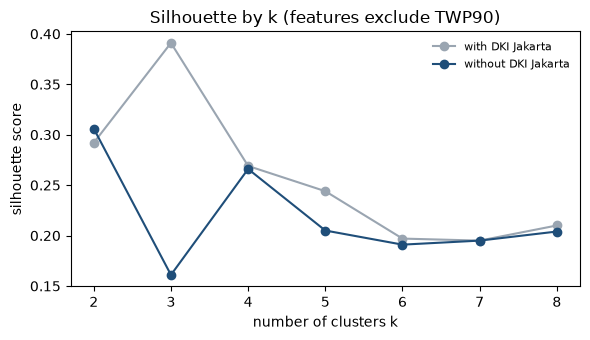

In [11]:
# Cell A11 - Choose k: silhouette with and without DKI Jakarta
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt

snap_ex = snap.drop(index="DKI Jakarta")


def scaled(frame):
    return StandardScaler().fit_transform(frame[CLUSTER_FEATS])


def silhouette_by_k(frame, ks):
    X = scaled(frame)
    return {k: round(float(silhouette_score(X, KMeans(k, n_init=20, random_state=SEED).fit(X).labels_)), 3) for k in ks}


KS = range(2, 9)
sil_all = silhouette_by_k(snap, KS)
sil_ex = silhouette_by_k(snap_ex, KS)
print(pd.DataFrame({"k": list(KS), "with_dki": list(sil_all.values()), "without_dki": list(sil_ex.values())}).to_string(index=False))
X_all = scaled(snap)
sizes_k3_all = np.bincount(KMeans(3, n_init=20, random_state=SEED).fit(X_all).labels_).tolist()
print(f"with_dki_k3_cluster_sizes={sorted(sizes_k3_all)}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(list(KS), list(sil_all.values()), "o-", color="#9aa5b1", label="with DKI Jakarta")
ax.plot(list(KS), list(sil_ex.values()), "o-", color="#1f4e79", label="without DKI Jakarta")
ax.set_xlabel("number of clusters k")
ax.set_ylabel("silhouette score")
ax.set_title("Silhouette by k (features exclude TWP90)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


### E.2 Kestabilan
ARI pada subsampel 80% dan persentase subsampel di mana provinsi tetap masuk ke cluster yang sama.

In [12]:
# Cell A12 - Stability of the partition: 80% subsamples and per-province agreement
X_ex = scaled(snap_ex)


def stability(X, k, n_boot=100):
    base = KMeans(k, n_init=20, random_state=SEED).fit(X).labels_
    boot_rng = np.random.default_rng(SEED)
    aris = []
    agree = np.zeros(len(X))
    for b in range(n_boot):
        idx = boot_rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
        km = KMeans(k, n_init=10, random_state=b).fit(X[idx])
        aris.append(adjusted_rand_score(base[idx], km.labels_))
        pred = km.predict(X)
        conf = pd.crosstab(base, pred).reindex(index=range(k), columns=range(k), fill_value=0).to_numpy()
        rows_i, cols_i = linear_sum_assignment(-conf)
        mapping = dict(zip(cols_i, rows_i))
        agree += np.array([mapping[p] == b0 for p, b0 in zip(pred, base)])
    return base, np.array(aris), agree / n_boot


stab = {k: stability(X_ex, k) for k in (2, 3, 4, 5)}
print(pd.DataFrame({
    "k": list(stab),
    "silhouette": [sil_ex[k] for k in stab],
    "ari_mean": [round(float(v[1].mean()), 2) for v in stab.values()],
    "ari_p10": [round(float(np.percentile(v[1], 10)), 2) for v in stab.values()],
}).to_string(index=False))
for k in (2, 4):
    agree = pd.Series(stab[k][2], index=snap_ex.index)
    unstable = agree[agree < 0.8].sort_values().round(2)
    print(f"k={k} provinces_with_agreement_below_0.8=", unstable.to_dict())


 k  silhouette  ari_mean  ari_p10
 2       0.306      0.55     0.17
 3       0.161      0.29     0.11
 4       0.266      0.53     0.17
 5       0.205      0.57     0.32
k=2 provinces_with_agreement_below_0.8= {'Sulawesi Barat': 0.19, 'Nusa Tenggara Timur': 0.2, 'Maluku': 0.4, 'Aceh': 0.44, 'Papua': 0.48, 'Papua Barat': 0.59, 'Papua Barat Daya': 0.72}
k=4 provinces_with_agreement_below_0.8= {'Kalimantan Timur': 0.46, 'Jawa Tengah': 0.48, 'Jawa Timur': 0.5, 'DI Yogyakarta': 0.54, 'Nusa Tenggara Timur': 0.54, 'Papua Tengah': 0.54, 'Sulawesi Utara': 0.56, 'Kepulauan Riau': 0.59, 'Nusa Tenggara Barat': 0.6, 'Sulawesi Barat': 0.61, 'Lampung': 0.63, 'Kalimantan Barat': 0.65, 'Bengkulu': 0.65, 'Sumatera Utara': 0.68, 'Gorontalo': 0.71, 'Riau': 0.74, 'Sulawesi Tenggara': 0.75, 'Sumatera Barat': 0.76, 'Papua Pegunungan': 0.76, 'Kalimantan Utara': 0.77, 'Maluku': 0.77}


### E.3 Profil cluster
k=2 sebagai pembagian utama dan k=4 sebagai pembacaan lebih halus. Cluster diberi nama C1, C2, dan seterusnya berurutan dari akun aktif per 100 penduduk tertinggi.

In [13]:
# Cell A13 - Cluster profiles for k=2 (primary) and k=4 (finer view)
PROFILE_COLS = ["twp90_median", "kemiskinan_pct", "ipm_score", "ump_idr", "accounts_per_100_pop", "log_debt_per_capita_idr", "log_penduduk_ribu"]


def label_clusters(frame, base_labels):
    tmp = frame.assign(_raw=base_labels)
    order = tmp.groupby("_raw")["accounts_per_100_pop"].mean().sort_values(ascending=False).index
    rename = {raw: f"C{i + 1}" for i, raw in enumerate(order)}
    return tmp["_raw"].map(rename)


snap_ex = snap_ex.assign(cluster_k2=label_clusters(snap_ex, stab[2][0]), cluster_k4=label_clusters(snap_ex, stab[4][0]))
for k in (2, 4):
    col = f"cluster_k{k}"
    prof = snap_ex.groupby(col)[PROFILE_COLS].mean().round(2)
    prof.insert(0, "n", snap_ex.groupby(col).size())
    print(f"profile {col}:")
    print(prof.to_string())
    for c in sorted(snap_ex[col].unique()):
        print(f"  {c}: {snap_ex.index[snap_ex[col] == c].tolist()}")


profile cluster_k2:
             n  twp90_median  kemiskinan_pct  ipm_score     ump_idr  accounts_per_100_pop  log_debt_per_capita_idr  log_penduduk_ribu
cluster_k2                                                                                                                           
C1          27          2.20            7.52      73.95  3174747.99                  4.37                    12.49               8.54
C2          10          1.13           18.96      67.09  3721701.57                  1.49                    10.99               7.30
  C1: ['Bali', 'Banten', 'Bengkulu', 'DI Yogyakarta', 'Gorontalo', 'Jambi', 'Jawa Barat', 'Jawa Tengah', 'Jawa Timur', 'Kalimantan Barat', 'Kalimantan Selatan', 'Kalimantan Tengah', 'Kalimantan Timur', 'Kalimantan Utara', 'Kepulauan Bangka Belitung', 'Kepulauan Riau', 'Lampung', 'Maluku Utara', 'Nusa Tenggara Barat', 'Riau', 'Sulawesi Selatan', 'Sulawesi Tengah', 'Sulawesi Tenggara', 'Sulawesi Utara', 'Sumatera Barat', 'Sumatera Selatan', '

### E.4 Perbandingan dengan hasil lama
Mengulang clustering yang memakai TWP90 sebagai fitur dan mengukur seberapa jauh partisinya berbeda.

In [14]:
# Cell A14 - Reproduce the original clustering (TWP90 as a feature) and compare
FRIEND_FEATS = CLUSTER_FEATS + ["twp90_mean"]
X_friend = StandardScaler().fit_transform(snap_ex[FRIEND_FEATS])
lab_friend = KMeans(3, n_init=10, random_state=SEED).fit(X_friend).labels_
lab_k3 = stab[3][0]
print(f"with_twp90_k3 sizes={sorted(np.bincount(lab_friend).tolist())} | silhouette={silhouette_score(X_friend, lab_friend):.3f}")
print(f"without_twp90_k3 sizes={sorted(np.bincount(lab_k3).tolist())} | silhouette={sil_ex[3]:.3f}")
print(f"ari_with_vs_without_twp90 k3={adjusted_rand_score(lab_friend, lab_k3):.2f} | vs_k2={adjusted_rand_score(lab_friend, stab[2][0]):.2f} | vs_k4={adjusted_rand_score(lab_friend, stab[4][0]):.2f}")

twp_by_friend = snap_ex.assign(f=lab_friend).groupby("f")["twp90_mean"].mean().round(2).sort_values()
print("twp90_mean_by_cluster_with_twp90_feature=", twp_by_friend.to_dict())


with_twp90_k3 sizes=[6, 10, 21] | silhouette=0.235
without_twp90_k3 sizes=[3, 16, 18] | silhouette=0.161
ari_with_vs_without_twp90 k3=0.14 | vs_k2=0.63 | vs_k4=0.40
twp90_mean_by_cluster_with_twp90_feature= {1: 1.2, 0: 2.06, 2: 3.3}


### E.5 Kasus khusus
DKI Jakarta (di luar cluster) dan NTB (provinsi dengan tren turun terbesar).

In [15]:
# Cell A15 - Special cases: DKI Jakarta (excluded) and Nusa Tenggara Barat
z_dki = ((snap.loc["DKI Jakarta", CLUSTER_FEATS] - snap_ex[CLUSTER_FEATS].mean()) / snap_ex[CLUSTER_FEATS].std()).round(1)
print("dki_feature_z_vs_other_37=", z_dki.sort_values(key=abs, ascending=False).head(4).to_dict())

ntb = "Nusa Tenggara Barat"
print(f"ntb cluster_k2={snap_ex.loc[ntb, 'cluster_k2']} | cluster_k4={snap_ex.loc[ntb, 'cluster_k4']} | twp90_median_12m={snap_ex.loc[ntb, 'twp90_median']:.2f}")
tw = df[df["province"] != "DKI Jakarta"].merge(snap_ex[["cluster_k4"]], left_on="province", right_index=True)
cluster_year = tw.groupby([tw["date"].dt.year, "cluster_k4"])["twp90_pct"].mean().unstack().round(2)
ntb_year_mean = df[df["province"] == ntb].groupby(df["date"].dt.year)["twp90_pct"].mean().round(2)
cluster_year["NTB"] = ntb_year_mean
print(cluster_year.to_string())


dki_feature_z_vs_other_37= {'accounts_per_100_pop': 7.6, 'ump_idr': 3.6, 'log_pdrb_perkapita_ribu_idr': 3.1, 'ipm_score': 2.2}
ntb cluster_k2=C1 | cluster_k4=C2 | twp90_median_12m=3.90


cluster_k4    C1    C2    C3    C4   NTB
date                                    
2023        2.68  2.01  1.48   NaN  6.50
2024        2.28  1.82  0.96  0.54  5.07
2025        2.33  2.11  1.17  1.22  4.04
2026        2.26  2.52  1.18  0.71  3.30


**Temuan bagian E.**
- **Reproduksi sahih.** Clustering lama (TWP90 sebagai fitur, k=3, tanpa Jakarta) menghasilkan ukuran cluster 21, 10, dan 6 dengan silhouette 0,235, sama dengan notebook teman.
- **Tanpa Jakarta, k=2 terbaik dan k=3 terburuk.** Silhouette 0,306 (k=2) vs 0,161 (k=3) vs 0,266 (k=4). Dengan Jakarta ikut, k=3 tampak 0,391 hanya karena Jakarta menjadi cluster singleton (ukuran 1, 5, dan 32). Stabilitas ARI pada subsampel 80%: k=2 0,55, k=3 0,29, k=4 0,53, k=5 0,57.
- **Strukturnya lemah.** Silhouette di bawah sekitar 0,31 dan ARI sekitar 0,55 berarti provinsi lebih tepat dibaca sebagai gradien ukuran pasar dan pembangunan daripada kelompok yang terpisah tegas. Tujuh provinsi berada di perbatasan pada k=2 (kesesuaian di bawah 0,8): Sulawesi Barat, NTT, Maluku, Aceh, Papua, Papua Barat, dan Papua Barat Daya.
- **TWP90 tetap berbeda antarcluster padahal bukan fitur.** k=2: C1 (27 provinsi) 2,20% vs C2 (10 provinsi, timur dan miskin) 1,13%. Pada k=4 perbedaannya bukan di antara cluster pasar besar: C1 (2,25%) dan C2 (2,13%) hampir sama, sedangkan C3 1,10% dan C4 0,92% jauh lebih rendah. Perbedaan utamanya adalah antara cluster pasar besar dan cluster timur dengan penetrasi rendah (akun 1,49 per 100 penduduk, kemiskinan 18,96% pada k=2).
- **Partisi lama lebih mirip pembagian dua.** ARI hasil lama (k=3) terhadap k=3 baru hanya 0,14, tetapi terhadap k=2 baru 0,63.
- **Jakarta** berjarak +7,6 simpangan baku dari 37 provinsi lain pada akun aktif per 100 penduduk, dan diperlakukan terpisah.
- **NTB tetap tinggi di dalam clusternya.** TWP90 median 12 bulannya, 3,90%, sama dengan maksimum 38 provinsi. NTB sekelompok dengan Jawa Tengah, Jawa Timur, dan DIY (cluster k=4 dengan rata-rata 2,13%), bukan dengan Jawa Barat dan Banten. Pada 2026 NTB 3,30% vs rata-rata clusternya 2,52%. Klaim lama bahwa risikonya mirip provinsi Jawa tidak didukung penuh.

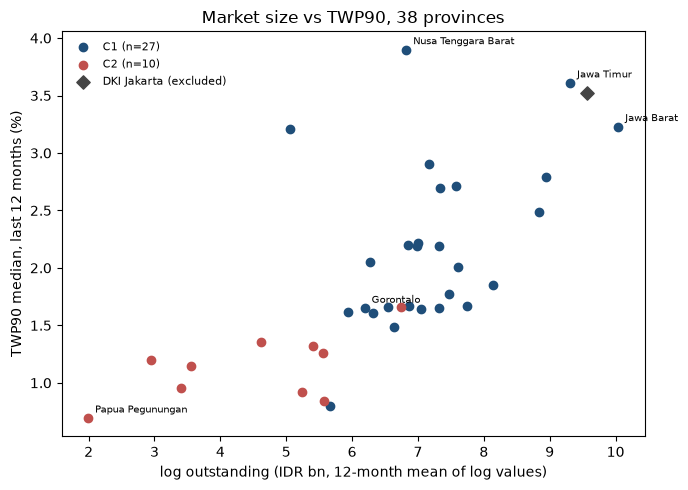

spearman_all_38=0.75
spearman_within_C1 n=27 = 0.46
spearman_within_C2 n=10 = 0.43
                     log_outstanding_miliar  twp90_median
province                                                 
Nusa Tenggara Barat                    6.82          3.90
Jawa Timur                             9.31          3.61
Jawa Barat                            10.04          3.23
Gorontalo                              6.19          1.65
Papua Pegunungan                       1.99          0.69


In [16]:
# Cell A16 - Market size vs TWP90 by cluster (k=2), DKI Jakarta marked
fig, ax = plt.subplots(figsize=(7, 5))
CLUSTER_COLORS = {"C1": "#1f4e79", "C2": "#c0504d"}
for c, g in snap_ex.groupby("cluster_k2"):
    ax.scatter(g["log_outstanding_miliar"], g["twp90_median"], color=CLUSTER_COLORS[c], s=36, label=f"{c} (n={len(g)})")
dki = snap.loc["DKI Jakarta"]
ax.scatter(dki["log_outstanding_miliar"], dki["twp90_median"], color="#444444", marker="D", s=46, label="DKI Jakarta (excluded)")
LABELED = ["Nusa Tenggara Barat", "Jawa Timur", "Jawa Barat", "Gorontalo", "Papua Pegunungan"]
for name in LABELED:
    ax.annotate(name, (snap.loc[name, "log_outstanding_miliar"], snap.loc[name, "twp90_median"]), textcoords="offset points", xytext=(5, 4), fontsize=7)
ax.set_xlabel("log outstanding (IDR bn, 12-month mean of log values)")
ax.set_ylabel("TWP90 median, last 12 months (%)")
ax.set_title("Market size vs TWP90, 38 provinces")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

print(f"spearman_all_38={stats.spearmanr(snap['log_outstanding_miliar'], snap['twp90_median']).statistic:.2f}")
for c, g in snap_ex.groupby("cluster_k2"):
    print(f"spearman_within_{c} n={len(g)} = {stats.spearmanr(g['log_outstanding_miliar'], g['twp90_median']).statistic:.2f}")
print(snap.loc[LABELED, ["log_outstanding_miliar", "twp90_median"]].round(2).to_string())


**Cara membaca grafik pencar (sel A16).** Setiap titik adalah satu provinsi. Korelasi Spearman antara outstanding dan TWP90 adalah 0,75 untuk 38 provinsi. Di dalam tiap cluster k=2 nilainya lebih rendah tetapi tetap positif: 0,46 pada C1 (n=27) dan 0,43 pada C2 (n=10). Jadi hubungan ukuran pasar dengan TWP90 bukan semata akibat perbedaan antara dua kelompok, tetapi sebagian dari kekuatannya memang berasal dari perbedaan itu. Nilai pada C2 berasal dari 10 provinsi saja dan karenanya sangat tidak pasti.

## L5. Validasi independen dan forensik

Bagian ini menguji hasil bagian B sampai F dengan kode baru dari file mentah, tanpa memakai `master_pindar_panel_clean.csv` sebagai sumber kebenaran:

1. Rekonsiliasi TWP90 nasional panel dengan baris `JUMLAH` resmi pada Tabel 9 workbook XLSX (sel A17).
2. Penurunan ulang TWP90 provinsi dari tabel kualitas SJKPublic (sel A18) dan uji identitas tabel 144.
3. Forensik lonjakan Jakarta 2025-11 dan 2025-12 menurut segmen dan bucket kualitas (sel A19).
4. Penggerak bulan lonjakan lain menurut segmen dan provinsi (sel A20).
5. Uji apakah selisih XLSX vs SJKPublic pada 2024-07 sampai 2024-10 berasal dari revisi antarrilis XLSX (sel A21).

Pengumuman OJK tentang peralihan publikasi hanya menyatakan bahwa mulai periode Januari 2026 statistik LPBBTI disajikan di Portal Data; pengumuman itu tidak menjelaskan selisih 2024-07 sampai 2024-10. Berkas `Mapping_Statistik_LPBBTI.xlsx` adalah peta antara tabel publikasi lama dan metrik portal, bukan kamus definisi; satu-satunya hal yang ditegaskannya adalah bahwa Tabel 9 resmi tersusun dari metrik kualitas pembiayaan per provinsi (1453/1454) dan metrik TWP90-DATI1 (144/312).

### L5.1 Rekonsiliasi dengan total nasional resmi
Baris `JUMLAH` pada sheet 9 diambil dari rilis terbaru untuk tiap bulan dan dibandingkan dengan TWP90 nasional tertimbang dari panel.

In [17]:
# Cell A17 - Reconcile with the official XLSX national total (independent sheet-9 parse)
xl_rows = []
for fp in sorted((RAW_DIR / "ojk_xlsx").glob("*.xlsx")):
    release = fp.stem.replace("ojk_lpbbti_", "")
    wb = openpyxl.load_workbook(fp, read_only=True, data_only=True)
    ws = wb[[s for s in wb.sheetnames if s.strip() == "9"][0]]
    sheet_rows = list(ws.iter_rows(min_row=1, max_row=60, values_only=True))
    wb.close()
    date_cols = [(j, parse_ojk_month_iso(v)) for j, v in enumerate(sheet_rows[1]) if j >= 2 and v is not None and parse_ojk_month_iso(v)]
    for r in sheet_rows[3:]:
        label = str(r[1]).strip() if len(r) > 1 and r[1] is not None else ""
        is_total = label.upper() == "JUMLAH"
        if not (is_total or re.match(r"^\d+\.", label)):
            continue
        prov = "TOTAL" if is_total else normalize_province(re.sub(r"^\d+\.\s*", "", label))[1]
        for j, d in date_cols:
            if j + 2 < len(r) and r[j + 1] is not None and r[j + 2] is not None:
                xl_rows.append((release, d, prov, float(r[j + 1]), float(r[j + 2]) * 100.0))
xl_rel = pd.DataFrame(xl_rows, columns=["release", "date", "prov", "out_miliar", "twp90_pct"])
print(f"xlsx_obs={len(xl_rel)} | releases={xl_rel['release'].nunique()} | dates={xl_rel['date'].min()}..{xl_rel['date'].max()}")

master_s = df.assign(date=df["date"].dt.strftime("%Y-%m-%d"))
nat_m = master_s.assign(mx=master_s["twp90_pct"] * master_s["outstanding_miliar"]).groupby("date").agg(mx=("mx", "sum"), out=("outstanding_miliar", "sum"))
nat_m["twp90_w"] = nat_m["mx"] / nat_m["out"]
xl_total = xl_rel[xl_rel["prov"] == "TOTAL"].sort_values(["date", "release"]).drop_duplicates("date", keep="last").set_index("date")
recon = nat_m.join(xl_total[["out_miliar", "twp90_pct"]], how="inner")
recon["d_twp90_pp"] = recon["twp90_w"] - recon["twp90_pct"]
recon["d_out_pct"] = (recon["out"] / recon["out_miliar"] - 1.0) * 100.0
before_splice = recon[recon.index < "2024-07-01"]
after_splice = recon[recon.index >= "2024-07-01"]
print(f"months={len(recon)} | xlsx_period max_abs_d_twp90_pp={before_splice['d_twp90_pp'].abs().max():.4f} | sjk_period max_abs_d_twp90_pp={after_splice['d_twp90_pp'].abs().max():.4f}")
worst = recon.reindex(recon["d_twp90_pp"].abs().sort_values(ascending=False).index).head(5)
print(worst[["twp90_w", "twp90_pct", "d_twp90_pp", "out", "out_miliar", "d_out_pct"]].round(3).to_string())
print(f"months_after_2024_10_with_abs_d_twp90_pp_gt_0.01={int((after_splice[after_splice.index > '2024-10-01']['d_twp90_pp'].abs() > 0.01).sum())}")


xlsx_obs=8941 | releases=18 | dates=2022-01-01..2025-12-01
months=36 | xlsx_period max_abs_d_twp90_pp=0.0020 | sjk_period max_abs_d_twp90_pp=0.0722
            twp90_w  twp90_pct  d_twp90_pp        out  out_miliar  d_out_pct
date                                                                        
2024-08-01    2.303      2.376      -0.072  71023.370   72033.441     -1.402
2024-09-01    2.306      2.375      -0.069  73305.901   74484.240     -1.582
2024-07-01    2.467      2.535      -0.068  68142.496   69393.360     -1.803
2024-10-01    2.362      2.367      -0.005  74267.851   75019.479     -1.002
2023-02-01    2.689      2.687       0.002  50050.747   50088.898     -0.076
months_after_2024_10_with_abs_d_twp90_pp_gt_0.01=0


### L5.2 Penurunan ulang dari tabel mentah
TWP90 provinsi dihitung ulang dari bucket kualitas pembiayaan (macet dibagi total outstanding, konvensional + syariah) dan dibandingkan dengan kolom di master. Tabel 144 diuji pada identitas: jumlahnya di seluruh provinsi harus sama dengan TWP90 nasional konvensional.

In [18]:
# Cell A18 - Re-derive provincial TWP90 from raw SJKPublic tables and check table 144
sjk_dir = RAW_DIR / "ojk_sjkpublic"
VAL_COL = "OutstandingPerseoranganKualitasPerDati"
QUAL_FILES = [
    ("konv", "1453_konv_borrower_kualitas_dati1_LPBBTI_PenerimaPinjamanKualitasPerDati.csv"),
    ("syar", "1454_syar_borrower_kualitas_dati1_LPBBTI_Syariah_PenerimaPinjamanKualitasPerDati.csv"),
]
parts = []
for seg, fn in QUAL_FILES:
    part = pd.read_csv(sjk_dir / fn)
    part["segment"] = seg
    parts.append(part)
sjk_q = pd.concat(parts, ignore_index=True)
sjk_q["date"] = sjk_q["Bulan"].astype(str) + "-01"
sjk_q["prov"] = sjk_q["DATI1"].map(lambda s: normalize_province(s)[1])

BUCKETS = ["lancar", "dpk", "kurang_lancar", "diragukan", "macet"]
qual = sjk_q.pivot_table(index=["date", "prov"], columns="KualitasPembiayaan", values=VAL_COL, aggfunc="sum").fillna(0.0) / 1e9
assert [c[:3] for c in qual.columns] == ["001", "002", "003", "004", "005"], "unexpected quality buckets"
qual.columns = BUCKETS
qual["out_miliar"] = qual[BUCKETS].sum(axis=1)
qual["twp90_pct"] = qual["macet"] / qual["out_miliar"] * 100.0

chk = qual.reset_index().merge(
    master_s[["date", "province", "twp90_pct", "outstanding_miliar"]],
    left_on=["date", "prov"], right_on=["date", "province"], how="left", suffixes=("_raw", "_master"), validate="one_to_one",
)
print(f"raw_rows={len(chk)} | matched_in_master={int(chk['twp90_pct_master'].notna().sum())} | max_abs_twp90_diff={(chk['twp90_pct_raw'] - chk['twp90_pct_master']).abs().max():.2e} | max_abs_out_diff={(chk['out_miliar'] - chk['outstanding_miliar']).abs().max():.2e}")

t144 = pd.read_csv(sjk_dir / "144_konv_twp90_dati1_LPBBTI_TWP90_DATI1.csv")
t144 = t144[~t144["NamaDATI1"].str.contains(r"Jawa$", regex=True)]
sum144 = t144.groupby("Bulan")["TWP90"].sum()
konv = sjk_q[sjk_q["segment"] == "konv"]
konv_nat = konv[konv["KualitasPembiayaan"].str.contains("005")].groupby("Bulan")[VAL_COL].sum() / konv.groupby("Bulan")[VAL_COL].sum() * 100.0
diff144 = (sum144 - konv_nat).dropna()
bad = diff144[diff144.abs() > 0.05]
print(f"table144_identity_months_ok={int((diff144.abs() <= 0.05).sum())} of {len(diff144)} | inconsistent_months={bad.round(2).to_dict()}")
print("table144_sum_by_inconsistent_month=", sum144.loc[bad.index].round(3).to_dict())
print(f"master_has_sjk_twp90_nat_share_pct={'sjk_twp90_nat_share_pct' in df.columns}")


raw_rows=836 | matched_in_master=836 | max_abs_twp90_diff=2.66e-15 | max_abs_out_diff=7.28e-12
table144_identity_months_ok=19 of 22 | inconsistent_months={'2025-03': 70.62, '2025-04': 76.12, '2025-05': -2.33}
table144_sum_by_inconsistent_month= {'2025-03': 73.39, '2025-04': 79.05, '2025-05': 0.846}
master_has_sjk_twp90_nat_share_pct=True


### L5.3 Forensik Jakarta 2025-11 dan 2025-12
Membagi macet Jakarta menurut bucket dan segmen (konvensional vs syariah), dan membandingkannya dengan seluruh provinsi lain.

In [19]:
# Cell A19 - Jakarta 2025-11/12: where did the macet come from?
JKT = "DKI Jakarta"
JKT_MONTHS = ["2025-09-01", "2025-10-01", "2025-11-01", "2025-12-01", "2026-01-01", "2026-02-01"]
jkt_rows = []
for d in JKT_MONTHS:
    p = qual.loc[d]
    jk, rest = p.loc[JKT], p.drop(index=JKT)
    jkt_rows.append({
        "date": d[:7], "jkt_macet": jk["macet"], "jkt_out": jk["out_miliar"], "jkt_twp90": jk["twp90_pct"],
        "rest_macet": rest["macet"].sum(), "rest_twp90": rest["macet"].sum() / rest["out_miliar"].sum() * 100.0,
        "nat_macet": p["macet"].sum(), "nat_twp90": p["macet"].sum() / p["out_miliar"].sum() * 100.0,
    })
print(pd.DataFrame(jkt_rows).round(2).to_string(index=False))
print(qual.xs(JKT, level="prov").loc[JKT_MONTHS, BUCKETS].round(1).to_string())

is_macet = sjk_q["KualitasPembiayaan"].str.contains("005")
jkt_seg = sjk_q[(sjk_q["prov"] == JKT) & is_macet & sjk_q["date"].isin(JKT_MONTHS)].groupby(["date", "segment"])[VAL_COL].sum().div(1e9).unstack()
print("jakarta_macet_by_segment:")
print(jkt_seg.round(1).to_string())

seg_out = sjk_q.groupby(["date", "segment"])[VAL_COL].sum().div(1e9).unstack()
seg_macet = sjk_q[is_macet].groupby(["date", "segment"])[VAL_COL].sum().div(1e9).unstack()
seg_tab = pd.DataFrame({
    "syar_out": seg_out["syar"], "syar_macet": seg_macet["syar"], "syar_twp90": seg_macet["syar"] / seg_out["syar"] * 100.0,
    "konv_out": seg_out["konv"], "konv_macet": seg_macet["konv"], "konv_twp90": seg_macet["konv"] / seg_out["konv"] * 100.0,
}).loc[["2025-04-01", "2025-10-01", "2025-11-01", "2025-12-01", "2026-01-01", "2026-02-01"]]
print("national_by_segment:")
print(seg_tab.round(2).to_string())


   date  jkt_macet  jkt_out  jkt_twp90  rest_macet  rest_twp90  nat_macet  nat_twp90
2025-09     553.97 15235.24       3.64     2006.93        2.65    2560.90       2.82
2025-10     548.35 15205.71       3.61     2012.94        2.59    2561.28       2.76
2025-11    1775.07 15361.23      11.56     2326.80        2.93    4101.87       4.33
2025-12    1808.98 15622.55      11.58     2365.08        2.92    4174.05       4.32
2026-01     472.91 14462.47       3.27     2161.37        2.64    2634.28       2.73
2026-02     513.24 14738.65       3.48     2694.04        3.19    3207.28       3.23
             lancar    dpk  kurang_lancar  diragukan   macet
date                                                        
2025-09-01  13118.9  742.4          445.6      374.4   554.0
2025-10-01  13133.7  713.4          466.4      343.9   548.3
2025-11-01  12215.5  647.6          383.9      339.1  1775.1
2025-12-01  12483.5  591.0          424.2      314.8  1809.0
2026-01-01  12509.6  651.9          450

### L5.4 Penggerak bulan lonjakan lain
Perubahan macet nasional antarbulan dipecah menurut segmen dan provinsi untuk 2025-06, 2025-11, dan 2026-02.

In [20]:
# Cell A20 - What drove the other spike months (national macet change by segment and province)
macet_ps = sjk_q[is_macet].pivot_table(index="prov", columns=["date", "segment"], values=VAL_COL, aggfunc="sum").div(1e9)
EVENTS = [("2025-05-01", "2025-06-01"), ("2025-10-01", "2025-11-01"), ("2026-01-01", "2026-02-01")]
for d0, d1 in EVENTS:
    for seg in ["konv", "syar"]:
        change = (macet_ps[(d1, seg)] - macet_ps[(d0, seg)]).dropna()
        top = change.sort_values(ascending=False).head(3).round(1)
        print(f"{d0[:7]}->{d1[:7]} {seg}: national_macet_change={change.sum():+.1f} | top_provinces={top.to_dict()} | top1_share_of_change={top.iloc[0] / change.sum() * 100.0:.0f}%")


2025-05->2025-06 konv: national_macet_change=-253.7 | top_provinces={'Banten': 7.0, 'Nusa Tenggara Timur': 0.9, 'Kalimantan Utara': 0.6} | top1_share_of_change=-3%
2025-05->2025-06 syar: national_macet_change=-2.4 | top_provinces={'Lampung': 0.0, 'Jawa Tengah': 0.0, 'Banten': 0.0} | top1_share_of_change=-0%
2025-10->2025-11 konv: national_macet_change=+317.0 | top_provinces={'Jawa Timur': 178.6, 'Banten': 42.9, 'Jawa Tengah': 33.2} | top1_share_of_change=56%
2025-10->2025-11 syar: national_macet_change=+1223.6 | top_provinces={'DKI Jakarta': 1225.8, 'Sumatera Selatan': 1.0, 'Jawa Timur': 0.7} | top1_share_of_change=100%
2026-01->2026-02 konv: national_macet_change=+573.0 | top_provinces={'Jawa Timur': 280.7, 'Jawa Barat': 65.8, 'Bali': 63.0} | top1_share_of_change=49%
2026-01->2026-02 syar: national_macet_change=-0.0 | top_provinces={'Jawa Barat': 0.1, 'Aceh': 0.0, 'Banten': 0.0} | top1_share_of_change=-2133%


### L5.5 Selisih XLSX vs SJKPublic, 2024-07 sampai 2024-10
Memeriksa apakah nilai XLSX berubah antarrilis (revisi) atau tetap, dan arah selisihnya terhadap SJKPublic.

In [21]:
# Cell A21 - Were the XLSX values for 2024-07..2024-10 restated across releases?
xs = xl_rel[(xl_rel["prov"] != "TOTAL") & xl_rel["date"].between("2024-07-01", "2024-10-01")].sort_values("release")
by_cell = xs.groupby(["date", "prov"])["out_miliar"]
cells = pd.DataFrame({
    "n_releases": xs.groupby(["date", "prov"])["release"].nunique(),
    "spread": by_cell.max() - by_cell.min(),
    "first": by_cell.first(),
    "last": by_cell.last(),
    "sjk": qual["out_miliar"],
}).dropna()
print(f"cells={len(cells)} | min_releases={int(cells['n_releases'].min())} | restated_across_releases={int((cells['spread'] > 0.01).sum())}")
print(f"abs_diff_xlsx_last_vs_sjk gt 0.5bn: {int(((cells['last'] - cells['sjk']).abs() > 0.5).sum())} of {len(cells)} | sjk_lower_than_xlsx: {int((cells['sjk'] < cells['last']).sum())}")
rel_gap = ((cells["sjk"] / cells["last"] - 1.0) * 100.0).groupby(level="date").median().round(2)
print("median_sjk_vs_xlsx_outstanding_pct_by_month=", rel_gap.to_dict())
print(cells.xs(JKT, level="prov").round(1).to_string())


cells=152 | min_releases=9 | restated_across_releases=0
abs_diff_xlsx_last_vs_sjk gt 0.5bn: 132 of 152 | sjk_lower_than_xlsx: 139
median_sjk_vs_xlsx_outstanding_pct_by_month= {'2024-07-01': -1.75, '2024-08-01': -1.33, '2024-09-01': -1.25, '2024-10-01': -1.1}
            n_releases  spread    first     last      sjk
date                                                     
2024-07-01         9.0     0.0  11907.8  11907.8  11696.5
2024-08-01        10.0     0.0  12276.8  12276.8  12105.6
2024-09-01        11.0     0.0  12370.0  12370.0  11947.3
2024-10-01        11.0     0.0  12584.8  12584.8  12499.3


### L5.6 Sensitivitas: TWP90 konvensional saja dan tanpa Jakarta
Mengulang asosiasi utama dengan TWP90 median yang hanya dihitung dari segmen konvensional (tanpa peristiwa syariah Jakarta), dan tanpa Jakarta sama sekali.

In [22]:
# Cell A22 - Sensitivity: conventional-only TWP90 and without DKI Jakarta
win_dates = sorted(rec["date"].dt.strftime("%Y-%m-%d").unique())
konv_q = sjk_q[sjk_q["segment"] == "konv"]
macet_k = konv_q[konv_q["KualitasPembiayaan"].str.contains("005")].groupby(["date", "prov"])[VAL_COL].sum()
out_k = konv_q.groupby(["date", "prov"])[VAL_COL].sum()
twp_k = (macet_k / out_k * 100.0).unstack()
snap_konv = twp_k.loc[win_dates].median().reindex(snap.index)
print(f"window_months={len(win_dates)} | konv_only_median_twp90 dki={snap_konv['DKI Jakarta']:.2f} vs combined={snap['twp90_median']['DKI Jakarta']:.2f}")

no_dki = snap.index != "DKI Jakarta"
checks = {
    "combined_all_38": (snap["twp90_median"], np.ones(len(snap), dtype=bool)),
    "combined_without_dki": (snap["twp90_median"], no_dki),
    "konv_only_all_38": (snap_konv, np.ones(len(snap), dtype=bool)),
    "konv_only_without_dki": (snap_konv, no_dki),
}
for name, (series, mask) in checks.items():
    rho_out = stats.spearmanr(snap.loc[mask, "log_outstanding_miliar"], series[mask]).statistic
    rho_acc = stats.spearmanr(snap.loc[mask, "accounts_per_100_pop"], series[mask]).statistic
    rho_poor = stats.spearmanr(snap.loc[mask, "kemiskinan_pct"], series[mask]).statistic
    print(f"{name} n={int(mask.sum())} | spearman log_outstanding={rho_out:.2f} | accounts_per_100_pop={rho_acc:.2f} | kemiskinan={rho_poor:.2f}")

by_cluster = pd.DataFrame({"combined": snap["twp90_median"], "konv_only": snap_konv}).loc[snap_ex.index].groupby(snap_ex["cluster_k2"]).mean().round(2)
print("twp90_by_cluster_k2:")
print(by_cluster.to_string())


window_months=12 | konv_only_median_twp90 dki=3.33 vs combined=3.52
combined_all_38 n=38 | spearman log_outstanding=0.75 | accounts_per_100_pop=0.62 | kemiskinan=-0.43
combined_without_dki n=37 | spearman log_outstanding=0.73 | accounts_per_100_pop=0.59 | kemiskinan=-0.40
konv_only_all_38 n=38 | spearman log_outstanding=0.72 | accounts_per_100_pop=0.62 | kemiskinan=-0.44


konv_only_without_dki n=37 | spearman log_outstanding=0.70 | accounts_per_100_pop=0.59 | kemiskinan=-0.41
twp90_by_cluster_k2:
            combined  konv_only
cluster_k2                     
C1              2.20       2.19
C2              1.13       1.13


**Temuan L5.**
- **Rekonsiliasi dengan angka resmi.** Pada periode XLSX (2023-01 sampai 2024-06), TWP90 nasional tertimbang dari panel berbeda dari baris `JUMLAH` resmi paling banyak 0,0020 poin persen. Pada periode SJKPublic perbedaannya terkonsentrasi di 2024-07 sampai 2024-10 (maksimum 0,072 poin; outstanding nasional 1,0 sampai 1,8% lebih rendah), dan sesudah 2024-10 tidak ada bulan dengan selisih di atas 0,01 poin. Untuk 2026-01 sampai 2026-04 tidak ada pembanding resmi di data lokal.
- **Penurunan ulang cocok.** TWP90 dan outstanding yang dihitung ulang dari tabel kualitas mentah cocok dengan master untuk 836 dari 836 baris provinsi-bulan (selisih maksimum 2,7e-15).
- **Tabel 144 tidak konsisten antarbulan.** Identitas "jumlah provinsi sama dengan TWP90 nasional konvensional" benar di 19 dari 22 bulan, tetapi jumlahnya 73,39 (2025-03), 79,05 (2025-04), dan 0,846 (2025-05) sementara bulan lain 2,3 sampai 3,3. Kolom `sjk_twp90_nat_share_pct` di master berasal dari tabel ini dan tidak boleh dipakai. TWP90 utama tidak terdampak.
- **Lonjakan Jakarta adalah satu peristiwa di segmen syariah, bukan artefak pelaporan.** Macet syariah Jakarta naik dari 107,4 miliar (2025-10) ke 1.333,1 (2025-11) dan 1.329,2 (2025-12), lalu turun ke 11,5 (2026-01). Macet konvensional Jakarta stabil (441,0, 441,9, 479,8). Kenaikan macet syariah nasional +1.223,6 miliar hampir seluruhnya Jakarta (+1.225,8). TWP90 segmen syariah nasional naik dari 9,30% ke 74,79%, lalu 11,97% di 2026-01, dan outstanding syariah nasional turun dari 1.850,7 (2025-12) ke 282,4 miliar (2026-01), sekitar 85%. Sebelumnya outstanding syariah tumbuh dari 1.012 (2025-04) ke 1.878 miliar (2025-10), sekitar 85%. Polanya adalah peristiwa kredit satu penyelenggara besar yang kemudian keluar atau dihapus buku. Penyelenggaranya tidak dapat dikenali dari data tingkat provinsi.
- **Lonjakan 2026-02 berasal dari segmen konvensional di Jawa Timur.** Macet konvensional nasional naik +573,0 miliar, 49% (+280,7) dari Jawa Timur, ditambah Jawa Barat +65,8 dan Bali +63,0; segmen syariah tidak berubah. Pada 2025-11 macet konvensional naik +317,0 miliar, 56% dari Jawa Timur (+178,6). Dua lonjakan itu menjelaskan rata-rata TWP90 Jawa Timur 2026 (5,37%) vs 2025 (3,41%) pada sel 19 notebook utama. Penyebabnya tidak dapat dikenali dari data provinsi.
- **Lonjakan 2025-06 adalah penurunan.** Macet konvensional nasional turun 253,7 miliar (sekitar 10%), tanpa provinsi yang naik berarti (Banten +7,0). Pola ini sesuai dengan penghapusan buku massal tetapi itu belum terbukti.
- **Selisih XLSX vs SJKPublic 2024-07 sampai 2024-10.** Nilai XLSX tidak pernah direvisi antarrilis (0 dari 152 sel berubah lintas sedikitnya 9 rilis). SJKPublic lebih rendah di 139 dari 152 sel, dengan median selisih -1,75% (2024-07), -1,33%, -1,25%, dan -1,10% (2024-10). Pengumuman OJK tidak menjelaskannya, sehingga untuk empat bulan itu angka resmi XLSX dan angka portal bersaing; panel memakai portal. Snapshot 12 bulan (2025-05 sampai 2026-04) tidak terpengaruh.
- **Asosiasi utama kokoh.** Spearman outstanding dengan TWP90: 0,75 untuk 38 provinsi, 0,72 dengan TWP90 konvensional saja, 0,73 tanpa Jakarta, dan 0,70 untuk keduanya. Akun per 100 penduduk 0,62 menjadi 0,59 sampai 0,62; kemiskinan -0,43 menjadi -0,40 sampai -0,44. Rata-rata TWP90 cluster k=2 hampir tidak berubah (C1 2,20 vs 2,19 konvensional; C2 1,13 vs 1,13).
- **Konsisten dengan H1 hanya untuk satu kasus.** Segmen syariah menunjukkan portofolio yang membesar cepat lalu gagal, tetapi itu satu penyelenggara dan bukan bukti bahwa portofolio muda menjelaskan TWP90 rendah di provinsi timur.
- **Belum dikerjakan:** uji lead-lag bucket DPK, Moran's I, uji ke depan dengan data bulan baru, dan replikasi pada TWP90 menurut jenis kelamin (regresi panel dengan efek tetap ada di bagian I).

## L6. Uji H1 dan regresi panel

H1 menyatakan bahwa TWP90 rendah di provinsi yang outstanding-nya tumbuh cepat karena penyebut membesar sebelum pinjaman baru jatuh tempo. Spesifikasi di bawah ditetapkan sebelum hasilnya dilihat.

- **Model.** `log(TWP90)` pada pertumbuhan outstanding `g_k = log(outstanding_t) - log(outstanding_{t-k})` dengan efek tetap provinsi dan bulan. Efek bulan menyerap kejadian lintas provinsi (2023-08, 2025-06, 2026-02) tanpa menyelidiki satu per satu; efek provinsi menyingkirkan perbedaan struktural antarprovinsi.
- **Prediksi.** Jika macet bulan t berasal dari pinjaman yang disalurkan sekitar k bulan lalu, koefisien `g_k` mendekati **-1** (macet sebanding dengan outstanding k bulan lalu, sehingga rasio turun satu-satu dengan pertumbuhan). Jika macet mengikuti outstanding saat ini, koefisien mendekati 0.
- **Horizon:** k = 3, 6, 9, 12. Semuanya dilaporkan.
- **Sampel utama:** 34 provinsi lama (tanpa empat Papua baru yang tumbuh dari hampir nol), 2024-01 sampai 2026-04.
- **Inferensi:** SE cluster per provinsi dan wild cluster bootstrap (bobot Rademacher, hipotesis nol dipaksakan, 999 replikasi). Dengan 34 cluster, p bootstrap lebih dapat dipercaya daripada p asimtotik.
- **Variabel sosial-ekonomi tidak masuk model**, karena nilainya konstan dalam provinsi dan terserap efek tetap provinsi (sel A7).

### L6.1 Persiapan
Pertumbuhan outstanding pada empat horizon, matriks desain dengan efek tetap, SE cluster, dan wild cluster bootstrap yang ditulis sendiri (tanpa paket tambahan).

In [23]:
# Cell A23 - Panel regression setup: growth horizons, two-way fixed effects, clustered and wild-bootstrap inference
panel = df.sort_values(["province", "date"]).copy()
panel["log_twp90"] = np.log(panel["twp90_pct"])
panel["log_out_exact"] = np.log(panel["outstanding_miliar"])
panel["macet_miliar"] = panel["twp90_pct"] / 100.0 * panel["outstanding_miliar"]
HORIZONS = [3, 6, 9, 12]
for k in HORIZONS:
    panel[f"g{k}"] = panel["log_out_exact"] - panel.groupby("province")["log_out_exact"].shift(k)
panel["f6"] = panel.groupby("province")["log_out_exact"].shift(-6) - panel["log_out_exact"]


def design(data, xcols, y="log_twp90"):
    d = data.dropna(subset=xcols + [y])
    prov = pd.get_dummies(d["province"], drop_first=True, dtype=float)
    mon = pd.get_dummies(d["date"].dt.strftime("%Y-%m"), drop_first=True, dtype=float)
    X = np.column_stack([d[xcols].to_numpy(float), prov.to_numpy(), mon.to_numpy(), np.ones(len(d))])
    return d, X, d[y].to_numpy(float), d["province"].to_numpy()


def ols_cluster(X, y, cl, xtx_inv=None):
    if xtx_inv is None:
        xtx_inv = np.linalg.pinv(X.T @ X)
    beta = xtx_inv @ (X.T @ y)
    resid = y - X @ beta
    meat = np.zeros((X.shape[1], X.shape[1]))
    for g in np.unique(cl):
        s = X[cl == g].T @ resid[cl == g]
        meat += np.outer(s, s)
    n_cl = len(np.unique(cl))
    n, kx = X.shape
    cov = xtx_inv @ meat @ xtx_inv * (n_cl / (n_cl - 1)) * ((n - 1) / (n - kx))
    return beta, np.sqrt(np.diag(cov)), resid


def wild_cluster_p(X, y, cl, j, n_boot=999, seed=SEED):
    xtx_inv = np.linalg.pinv(X.T @ X)
    beta, se, _ = ols_cluster(X, y, cl, xtx_inv)
    t_obs = beta[j] / se[j]
    X0 = np.delete(X, j, axis=1)
    fit0 = X0 @ (np.linalg.pinv(X0.T @ X0) @ (X0.T @ y))
    u0 = y - fit0
    groups, gi = np.unique(cl, return_inverse=True)
    boot_rng = np.random.default_rng(seed)
    hits = 0
    for _ in range(n_boot):
        w = boot_rng.choice([-1.0, 1.0], size=len(groups))[gi]
        b_s, se_s, _ = ols_cluster(X, fit0 + w * u0, cl, xtx_inv)
        hits += abs(b_s[j] / se_s[j]) >= abs(t_obs)
    return (hits + 1) / (n_boot + 1)


def estimate(data, xcols, label, n_boot=999):
    d, X, y, cl = design(data, xcols)
    beta, se, _ = ols_cluster(X, y, cl)
    n_cl = len(np.unique(cl))
    crit = stats.t.ppf(0.975, n_cl - 1)
    return [{
        "spec": label, "term": name, "coef": beta[j], "se": se[j],
        "ci_lo": beta[j] - crit * se[j], "ci_hi": beta[j] + crit * se[j],
        "wild_p": wild_cluster_p(X, y, cl, j, n_boot), "n": len(d), "clusters": n_cl,
    } for j, name in enumerate(xcols)]


MAIN = panel[~panel["province"].isin(NEW_PROVS) & (panel["date"] >= "2024-01-01")]
print(f"main_sample provinces={MAIN['province'].nunique()} | months={MAIN['date'].nunique()} | rows={len(MAIN)} | span={MAIN['date'].min():%Y-%m}..{MAIN['date'].max():%Y-%m}")
print(f"growth_log_points median g6={MAIN['g6'].median():.3f} | p10..p90 g6={MAIN['g6'].quantile(0.1):.3f}..{MAIN['g6'].quantile(0.9):.3f}")


main_sample provinces=34 | months=28 | rows=952 | span=2024-01..2026-04
growth_log_points median g6=0.159 | p10..p90 g6=0.067..0.278


### L6.2 Uji utama
Tiap baris adalah satu regresi. `t_vs_minus_1` menguji apakah koefisien berbeda dari -1.

In [24]:
# Cell A24 - H1 main test: TWP90 against past outstanding growth, province and month fixed effects
main_rows = []
for k in HORIZONS:
    main_rows += estimate(MAIN, [f"g{k}"], f"main_g{k}")
main_tab = pd.DataFrame(main_rows)
main_tab["twp90_change_pct_per_10pct_growth"] = np.expm1(main_tab["coef"] * np.log(1.10)) * 100.0
main_tab["t_vs_minus_1"] = (main_tab["coef"] + 1.0) / main_tab["se"]
print(main_tab[["spec", "coef", "se", "ci_lo", "ci_hi", "wild_p", "t_vs_minus_1", "twp90_change_pct_per_10pct_growth", "n", "clusters"]].round(3).to_string(index=False))


    spec   coef    se  ci_lo  ci_hi  wild_p  t_vs_minus_1  twp90_change_pct_per_10pct_growth   n  clusters
 main_g3 -0.453 0.393 -1.253  0.346   0.275         1.391                             -4.229 952        34
 main_g6 -0.570 0.383 -1.350  0.210   0.213         1.121                             -5.288 952        34
 main_g9 -0.597 0.365 -1.339  0.145   0.199         1.105                             -5.531 952        34
main_g12 -0.548 0.351 -1.261  0.165   0.207         1.289                             -5.090 952        34


### L6.3 Robustness
Tanpa Jakarta (peristiwa syariah), dengan empat provinsi Papua baru, dengan kontrol (outstanding dan akun per 100 penduduk), dan uji plasebo memakai pertumbuhan **masa depan** (seharusnya tidak berkaitan dengan TWP90 saat ini jika efeknya benar-benar penyebut).

In [25]:
# Cell A25 - Robustness: without Jakarta, with new Papua provinces, controls, and a placebo on future growth
all_2024 = panel[panel["date"] >= "2024-01-01"]
robust_rows = []
for k in (6, 12):
    robust_rows += estimate(MAIN[MAIN["province"] != "DKI Jakarta"], [f"g{k}"], f"no_dki_g{k}")
    robust_rows += estimate(all_2024, [f"g{k}"], f"with_new_papua_g{k}")
robust_rows += estimate(MAIN, ["g6", "log_out_exact", "accounts_per_100_pop"], "controls")
robust_rows += estimate(MAIN, ["f6"], "placebo_future_growth_6m")
robust_tab = pd.DataFrame(robust_rows)
print(robust_tab[["spec", "term", "coef", "se", "ci_lo", "ci_hi", "wild_p", "n", "clusters"]].round(3).to_string(index=False))


                    spec                 term   coef    se  ci_lo  ci_hi  wild_p    n  clusters
               no_dki_g6                   g6 -0.702 0.388 -1.493  0.089   0.168  924        33
       with_new_papua_g6                   g6  0.087 0.162 -0.241  0.416   0.601 1016        38
              no_dki_g12                  g12 -0.622 0.359 -1.353  0.109   0.189  924        33
      with_new_papua_g12                  g12 -0.144 0.207 -0.563  0.276   0.534  992        38
                controls                   g6 -0.513 0.382 -1.291  0.265   0.281  952        34
                controls        log_out_exact  0.077 0.285 -0.503  0.658   0.787  952        34
                controls accounts_per_100_pop -0.056 0.026 -0.109 -0.002   0.020  952        34
placebo_future_growth_6m                   f6  0.355 0.341 -0.340  1.050   0.317  748        34


### L6.4 Lintas provinsi dengan penyebut bermundur
Membandingkan TWP90 biasa dengan macet saat ini dibagi outstanding 6 dan 12 bulan lalu pada dua cluster k=2. Jika H1 menjelaskan jurang timur-barat, jurangnya menyusut saat penyebut dibuat bermundur.

In [26]:
# Cell A26 - Cross-section: does a lagged denominator shrink the east-west TWP90 gap?
for k in (6, 12):
    panel[f"twp90_lag{k}_pct"] = panel["macet_miliar"] / panel.groupby("province")["outstanding_miliar"].shift(k) * 100.0
panel["growth12_pct"] = (panel["outstanding_miliar"] / panel.groupby("province")["outstanding_miliar"].shift(12) - 1.0) * 100.0
win_panel = panel[panel["date"] > panel["date"].max() - pd.DateOffset(months=12)]
cs = win_panel.groupby("province")[["twp90_pct", "twp90_lag6_pct", "twp90_lag12_pct", "growth12_pct"]].median()
cs = cs.join(snap_ex[["cluster_k2"]], how="inner")
by_cluster = cs.groupby("cluster_k2").agg(
    n=("twp90_pct", "size"), twp90=("twp90_pct", "mean"), lag6=("twp90_lag6_pct", "mean"),
    lag12=("twp90_lag12_pct", "mean"), growth12_pct=("growth12_pct", "median"),
)
print(by_cluster.round(2).to_string())
gap_rows = {
    "current": by_cluster.loc["C1", "twp90"] / by_cluster.loc["C2", "twp90"],
    "lag6": by_cluster.loc["C1", "lag6"] / by_cluster.loc["C2", "lag6"],
    "lag12": by_cluster.loc["C1", "lag12"] / by_cluster.loc["C2", "lag12"],
}
print("c1_over_c2_ratio=", {k: round(float(v), 2) for k, v in gap_rows.items()})
cs = cs.join(snap_ex[["log_outstanding_miliar"]])
for col in ["twp90_pct", "twp90_lag6_pct", "twp90_lag12_pct"]:
    ok = cs[col].notna()
    print(f"spearman_with_log_outstanding {col}={stats.spearmanr(cs.loc[ok, 'log_outstanding_miliar'], cs.loc[ok, col]).statistic:.2f} n={int(ok.sum())}")


             n  twp90  lag6  lag12  growth12_pct
cluster_k2                                      
C1          27   2.20  2.53   2.93         34.29
C2          10   1.13  1.38   1.86         52.54
c1_over_c2_ratio= {'current': 1.94, 'lag6': 1.83, 'lag12': 1.58}
spearman_with_log_outstanding twp90_pct=0.73 n=37
spearman_with_log_outstanding twp90_lag6_pct=0.72 n=37
spearman_with_log_outstanding twp90_lag12_pct=0.65 n=37


### L6.5 Tanpa empat Papua baru
Empat dari sepuluh provinsi di C2 adalah Papua baru yang tumbuh sangat cepat dari dasar yang hampir nol. Sel ini mengulang perbandingan I.4 tanpa keempatnya, untuk melihat apakah provinsi mapan di C2 juga tumbuh lebih cepat.

In [27]:
# Cell A27 - Same comparison without the four new Papua provinces
est = cs[~cs.index.isin(NEW_PROVS)]
est_cluster = est.groupby("cluster_k2").agg(
    n=("twp90_pct", "size"), twp90=("twp90_pct", "mean"), lag6=("twp90_lag6_pct", "mean"),
    lag12=("twp90_lag12_pct", "mean"), growth12_pct=("growth12_pct", "median"),
)
print(est_cluster.round(2).to_string())
print("c1_over_c2_ratio=", {name: round(float(est_cluster.loc["C1", col] / est_cluster.loc["C2", col]), 2) for name, col in [("current", "twp90"), ("lag6", "lag6"), ("lag12", "lag12")]})
print(est[est["cluster_k2"] == "C2"][["twp90_pct", "twp90_lag12_pct", "growth12_pct"]].sort_values("growth12_pct", ascending=False).round(2).to_string())


             n  twp90  lag6  lag12  growth12_pct
cluster_k2                                      
C1          27   2.20  2.53   2.93         34.29
C2           6   1.23  1.41   1.72         30.35
c1_over_c2_ratio= {'current': 1.8, 'lag6': 1.8, 'lag12': 1.71}
                     twp90_pct  twp90_lag12_pct  growth12_pct
province                                                     
Nusa Tenggara Timur       1.66             2.83         57.98
Maluku                    0.84             1.23         47.10
Papua Barat               1.36             1.76         31.69
Sulawesi Barat            1.26             1.65         29.02
Papua                     1.32             1.81         26.03
Aceh                      0.92             1.01          4.72


**Temuan L6.**
- **H1 tidak terbukti sebagai penjelasan jurang timur-barat.** Koefisien pertumbuhan outstanding negatif pada semua horizon: -0,45 (k=3), -0,57 (k=6), -0,60 (k=9), -0,55 (k=12). Arahnya sesuai H1, tetapi tidak signifikan (wild p 0,20 sampai 0,28) dan interval kepercayaan 95% lebar: pada k=6 dari -1,35 sampai +0,21, mencakup 0 (tidak ada efek) dan -1 (efek penuh). Jika nyata, besarnya sekitar 5% lebih rendah TWP90 untuk setiap 10% pertumbuhan outstanding.
- **Hasilnya rapuh.** Tanpa Jakarta, koefisien k=6 menjadi -0,70 (p 0,17), tetapi dengan empat provinsi Papua baru ia hilang: +0,09 (p 0,60) pada k=6 dan -0,14 (p 0,53) pada k=12. Uji plasebo dengan pertumbuhan masa depan bertanda positif (+0,36; p 0,32), jadi hubungan negatif itu bukan artefak mekanis dari struktur data.
- **Pada provinsi mapan, cluster timur tidak tumbuh lebih cepat.** Tanpa Papua baru, median pertumbuhan outstanding 12 bulan sekitar 30% pada C2 (n=6) dan 34% pada C1 (n=27). Rasio TWP90 C1 terhadap C2 praktis tidak berubah ketika penyebut dibuat bermundur (1,80 menjadi 1,71 pada lag 12), sedangkan dengan Papua baru rasio itu menyusut dari 1,94 ke 1,58. Penyusutan itu hampir seluruhnya efek keempat provinsi baru (tumbuh 89 sampai 122%). Aceh adalah contoh lawan: pertumbuhannya hanya 4,7% tetapi TWP90-nya 0,92%.
- **Kesimpulan untuk H1:** efek penyebut mungkin ada (arah dan besar konsisten dengan model portofolio muda, dan terlihat jelas pada segmen syariah di bagian H), tetapi pada data ini ia tidak menjelaskan mengapa provinsi timur yang mapan memiliki TWP90 lebih rendah. Faktor lain (H2 sampai H4) masih terbuka.
- **Temuan sampingan: tanda berbalik antara antarprovinsi dan dalam provinsi.** Antarprovinsi, akun per 100 penduduk berkorelasi positif dengan TWP90 (Spearman 0,62; sel A9). Dalam provinsi, setelah efek tetap, koefisiennya negatif: -0,056 per tambahan satu akun per 100 penduduk (CI -0,109 sampai -0,002; wild p 0,020), sekitar 5,4% TWP90 lebih rendah. Ini satu dari 12 koefisien yang diuji (4 uji utama dan 8 baris robustness) tanpa koreksi banyak perbandingan, jadi bersifat eksploratif. Penjelasan yang paling sederhana adalah akun yang baru dibuka belum sempat menunggak, tetapi data ini tidak membuktikannya.

## L7. Interpretasi versi lengkap

Bagian ini menulis ulang kesimpulan dengan batas yang ditopang data. Angka merujuk ke sel di bagian C, D, dan E.

### F.1 Yang ditopang data

1. **TWP90 adalah ciri provinsi yang cukup stabil.** 63% varians TWP90 adalah varians antarprovinsi (sel A10). Sisa 37% adalah variasi antarwaktu dalam provinsi, termasuk tren turun NTB dan lonjakan sementara seperti Jakarta.
2. **Provinsi dengan pasar lebih besar dan penetrasi lebih tinggi cenderung punya TWP90 lebih tinggi.** Spearman antarprovinsi (n=38): outstanding 0,75 (CI 0,48 sampai 0,90), penduduk 0,67, akun per 100 penduduk 0,62 (sel A9). Untuk penetrasi dan utang per kapita hubungan itu bertahan setelah ukuran penduduk ditahan (0,44 dan 0,38; sel A10), dan juga di dalam tiap cluster k=2 (outstanding: 0,46 pada C1 dan 0,43 pada C2; sel A16).
3. **Kemiskinan berasosiasi negatif, bukan nol.** Spearman -0,43 (CI -0,68 sampai -0,10); melemah menjadi -0,24 setelah penduduk ditahan. Provinsi lebih miskin cenderung punya TWP90 lebih rendah.
4. **Ada dua kelompok kasar, dengan batas yang lembek.** k=2: 27 provinsi dengan TWP90 median 2,20% dan 10 provinsi timur dengan 1,13% (sel A13). Perbedaan TWP90 ini bukan akibat definisi cluster karena TWP90 tidak dipakai sebagai fitur. Silhouette 0,31 dan stabilitas ARI 0,55 berarti ini lebih mirip gradien daripada dua kelompok terpisah; tujuh provinsi berada di perbatasan (sel A12).
5. **Dua kasus khusus.** DKI Jakarta (akun per 100 penduduk +7,6 simpangan baku dari provinsi lain; TWP90 2025-11 dan 2025-12 didorong satu segmen syariah; lihat bagian H) dan NTB (TWP90 turun dari 6,50% ke 3,30% tetapi tetap tertinggi di 38 provinsi pada 12 bulan terakhir).

### F.2 Yang tidak ditopang data (koreksi dari kesimpulan awal)

- **"Gagal bayar dipengaruhi besar pasar, bukan kemiskinan."** Yang ditopang hanya: *berasosiasi* dengan ukuran pasar dan penetrasi pada 38 provinsi. Hubungan itu tidak muncul di dalam provinsi (korelasi within-province 0,10 untuk outstanding dan -0,05 untuk akun; sel A10), jadi tidak ada bukti bahwa membesarnya pasar menaikkan TWP90.
- **"Pinjol sedikit berarti TWP90 otomatis kecil karena akses internet terbatas."** Tidak ada variabel akses internet di data, sehingga ini hipotesis (H2 di bawah). TWP90 juga rasio, bukan jumlah.
- **Penjelasan berbasis cluster.** Pada notebook awal, cluster dibentuk dengan TWP90 sebagai fitur lalu dijelaskan dengan TWP90. Setelah TWP90 dikeluarkan, partisinya berubah banyak (ARI 0,14 pada k=3; sel A14).
- **"NTB mirip provinsi Jawa."** NTB sekelompok dengan Jawa Tengah, Jawa Timur, dan DIY pada k=4, tetapi TWP90 2026-nya 3,30% vs 2,52% rata-rata clusternya (sel A15).

### F.3 Hipotesis yang belum diuji

| | Hipotesis | Data yang menguji |
|---|---|---|
| H1 | TWP90 rendah di provinsi timur karena portofolionya muda (outstanding tumbuh cepat sehingga penyebut membesar sebelum pinjaman jatuh tempo). Diuji di bagian I: arah sesuai tetapi tidak signifikan, hilang saat Papua baru disertakan, dan provinsi mapan di cluster timur tidak tumbuh lebih cepat, jadi tidak menjelaskan jurangnya | umur pinjaman atau kualitas pembiayaan per kohort penyaluran |
| H2 | Akses internet dan penetrasi aplikasi menjelaskan TWP90 rendah | indikator akses internet BPS per provinsi |
| H3 | Komposisi platform (platform tertentu menyalurkan lebih banyak di provinsi tertentu) menjelaskan perbedaan level | outstanding dan TWP90 per platform per provinsi |
| H4 | Pemberi pinjaman menyaring lebih ketat di provinsi miskin, sehingga TWP90 rendah | tingkat penolakan atau limit per provinsi |
| H5 | Lonjakan Jakarta 2025-11 dan 2025-12 adalah kegagalan satu penyelenggara syariah besar yang kemudian keluar atau dihapus buku (bukan artefak pelaporan; bagian H.3) | identitas penyelenggara per segmen dan provinsi, pengumuman OJK tentang penyelenggara itu |
| H6 | Lonjakan 2026-02 didorong beberapa penyelenggara konvensional besar di Jawa Timur (+281 dari +573 miliar macet nasional; bagian H.4); lonjakan 2023-08 dan 2025-06 belum dijelaskan | TWP90 per platform pada bulan-bulan itu |

### F.4 Batasan

- **n=38 provinsi.** CI lebar, korelasi parsial tanpa CI, dan struktur cluster lemah. Tidak ada uji signifikansi yang dikoreksi untuk banyak perbandingan.
- **Analisis ekologis.** Semua hubungan berlaku di tingkat provinsi, bukan di tingkat peminjam.
- **Variabel sosial-ekonomi nyaris statis.** 92 sampai 99,6% variansnya antarprovinsi, dan IPM 2025 dan 2026 serta kemiskinan dan PDRB 2026 adalah salinan tahun sebelumnya (sel A7). Hubungan within-province untuk variabel ini tidak dapat diuji.
- **Sambungan sumber data.** TWP90 2024-07 sampai 2024-10 dihitung dari SJKPublic yang berbeda dari XLSX di sekitar 90% provinsi (sel 10 notebook utama). Selisihnya bukan revisi XLSX (0 dari 152 sel berubah antarrilis; sel A21): SJKPublic lebih rendah 1,1 sampai 1,8% pada median outstanding provinsi, dan data ini tidak menjelaskan penyebabnya.
- **Snapshot 12 bulan** (2025-05 sampai 2026-04) memuat lonjakan Jakarta dan lonjakan lintas provinsi 2026-02; median dipakai untuk membatasi dampaknya, tetapi tidak menghilangkannya.
- **Papua baru** hanya punya 22 bulan dan outstanding sangat kecil (0,11% dari total).
- **Tidak ada inferensi kausal.** Tidak ada desain identifikasi (DiD, variabel instrumen, atau eksperimen).